# День 1 — Архитектура трансформеров и токенизация

Токенизатор превращает текст в числовые ID. Трансформер превращает эти ID в векторы и с помощью attention учитывает связи между токенами. Сегодня работаем с токенизатором, в День 2 — с моделью.

## Подготовка после клонирования репозитория

Сначала установите `requirements.txt`. Следующая ячейка скачает SST-2 и базовый DistilBERT по фиксированным ревизиям, проверит SHA-256 и воспроизведёт CSV. Fine-tuned модель восстанавливается из поставляемой папки `model_bundle`. При повторном запуске используются готовые файлы.

In [ ]:
from project_setup import prepare_project

prepare_project();

## Задача 1. Установка и импорты

В окружении проекта библиотеки уже установлены. Для установки в новом окружении выполните в ячейке:

```python
%pip install transformers torch
```

В VS Code выберите ядро `.venv` проекта или **Python (transformers-week)**.

In [1]:
from transformers import AutoTokenizer
import torch

## Задача 2. Загрузка токенизатора

Для наших английских текстов используем `distilbert-base-uncased`. Его токенизатор уже скачан в папку проекта, поэтому загружаем локально.

`vocab_size` — размер словаря, `model_max_length` — максимальное число токенов во входе.

In [2]:
model_name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(
    "artifacts/day01/tokenizer", local_files_only=True
)
print("Размер словаря:", tokenizer.vocab_size)
print("Максимальная длина:", tokenizer.model_max_length)

Размер словаря: 30522
Максимальная длина: 512


## Задача 3. Токенизация текста

`input_ids` содержит номера токенов. Токенизатор добавляет `[CLS]` в начало и `[SEP]` в конец. `decode` собирает строку обратно; исходный регистр у `uncased` не сохраняется.

In [3]:
text = "This movie was absolutely amazing!"
tokens = tokenizer(text)
print(tokens)

input_ids = tokens["input_ids"]
print(f"Количество токенов: {len(input_ids)}")

decoded = tokenizer.decode(input_ids)
print(f"Декодировано: {decoded}")

{'input_ids': [101, 2023, 3185, 2001, 7078, 6429, 999, 102], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}
Количество токенов: 8
Декодировано: [CLS] this movie was absolutely amazing! [SEP]


## Задача 4. Работа с батчами

Батч — несколько текстов вместе. `padding=True` дополняет короткие строки до самой длинной в батче. `truncation=True` обрезает входы до `max_length`, включая спецтокены. `return_tensors="pt"` возвращает тензоры PyTorch.

Токенизатор передаём явно через `tokenizer=...`, чтобы использовать ту же функцию в День 2.

In [4]:
def tokenize_texts(texts, max_length=128, *, tokenizer):
    return tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    )

Два текста задаются в списке `texts` ниже. Форма результата — `[количество текстов, длина после padding]`. В маске `1` обозначает полезную позицию, `0` — padding. Это ещё не веса внимания модели.

In [5]:
texts = [
    "This movie was great!",
    "Terrible movie, waste of time.",
]

tokens = tokenize_texts(texts, tokenizer=tokenizer)
print(f'Shape: {tokens["input_ids"].shape}')
print(f'Attention mask:\n{tokens["attention_mask"]}')

Shape: torch.Size([2, 9])
Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1]])


## Задача 5. Специальные токены

`[CLS]` — начало входа, `[SEP]` — конец или разделитель, `[PAD]` — дополнение для выравнивания длин. У `[CLS]` и `[SEP]` маска равна `1`.

In [6]:
print(f"CLS token: {tokenizer.cls_token} (ID: {tokenizer.cls_token_id})")
print(f"SEP token: {tokenizer.sep_token} (ID: {tokenizer.sep_token_id})")
print(f"PAD token: {tokenizer.pad_token} (ID: {tokenizer.pad_token_id})")

single = tokenizer(text, return_tensors="pt")
print(f'Input IDs: {single["input_ids"]}')
print(f'Decoded: {tokenizer.decode(single["input_ids"][0])}')

CLS token: [CLS] (ID: 101)
SEP token: [SEP] (ID: 102)
PAD token: [PAD] (ID: 0)
Input IDs: tensor([[ 101, 2023, 3185, 2001, 7078, 6429,  999,  102]])
Decoded: [CLS] this movie was absolutely amazing! [SEP]


## Задача 6. Функция explain_tokenization

`.tokenize()` показывает токены без автоматически добавляемых `[CLS]` и `[SEP]`. Затем переводим их в ID. Поэтому количество здесь на два меньше, чем при обычном вызове `tokenizer(text)` для одного текста.

In [7]:
def explain_tokenization(text, tokenizer):
    tokens = tokenizer.tokenize(text)
    ids = tokenizer.convert_tokens_to_ids(tokens)
    print(f"Исходный текст: {text}")
    print(f"Токены: {tokens}")
    print(f"IDs: {ids}")
    print(f"Количество: {len(tokens)}")

explain_tokenization("Transformers are amazing!", tokenizer)

Исходный текст: Transformers are amazing!
Токены: ['transformers', 'are', 'amazing', '!']
IDs: [19081, 2024, 6429, 999]
Количество: 4


**Чекпоинт Дня 1:** загружен токенизатор; готовы функции `tokenize_texts` и `explain_tokenization`.

# День 2 — Получение эмбеддингов (hidden states)

Продолжайте после ячеек Дня 1. Hidden state — вектор признаков токена с учётом контекста. Для DistilBERT в одном векторе 768 чисел.

## Задача 1. Загрузка модели

Загружаем уже скачанные веса того же checkpoint, что и токенизатор. `AutoModel` возвращает базовый трансформер без классификатора тональности.

`model.eval()` выключает режим обучения, например случайный dropout. Сам по себе этот вызов не отключает вычисление градиентов.

In [8]:
from transformers import AutoModel

model = AutoModel.from_pretrained(
    "artifacts/day02/model", local_files_only=True
)
model.eval()
print(model)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSdpaAttention(
          (dropout): Dropout(p=0.1, inplace=False)
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

## Задача 2. Hidden states для одного текста

`model(**tokens)` передаёт модели `input_ids` и `attention_mask` из словаря. `torch.no_grad()` отключает запись операций для вычисления градиентов: сейчас модель не обучаем.

Форма `last_hidden_state`: `[число текстов, число токенов, размер вектора]`.

In [9]:
text = "This movie was absolutely amazing!"
tokens = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model(**tokens)

print(type(outputs))
print(outputs.last_hidden_state.shape)

<class 'transformers.modeling_outputs.BaseModelOutput'>
torch.Size([1, 8, 768])


`[:, 0, :]` выбирает все тексты, первую позицию `[CLS]` и все признаки. Получается один вектор на текст — `[число текстов, 768]`. Его используем как представление текста.

In [10]:
cls_embedding = outputs.last_hidden_state[:, 0, :]
print(f"CLS embedding shape: {cls_embedding.shape}")
print(f"CLS embedding: {cls_embedding[0][:5]}...")

CLS embedding shape: torch.Size([1, 768])
CLS embedding: tensor([ 0.0682, -0.0685,  0.1918,  0.0139, -0.0544])...


## Задача 3. Функция get_embeddings

Цикл берёт по `batch_size` текстов, вызывает функцию токенизации Дня 1 и пропускает батч через модель. Затем выбирает `[CLS]`.

`.cpu().numpy()` переводит тензор в массив NumPy на CPU, а `np.vstack` объединяет батчи в исходном порядке. В этом задании модель и входы работают на CPU.

In [11]:
import numpy as np


def get_embeddings(texts, tokenizer, model, batch_size=32):
    all_embeddings = []
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        tokens = tokenize_texts(batch_texts, max_length=128, tokenizer=tokenizer)

        with torch.no_grad():
            outputs = model(**tokens)

        cls_embeddings = outputs.last_hidden_state[:, 0, :]
        all_embeddings.append(cls_embeddings.cpu().numpy())

    return np.vstack(all_embeddings)

## Задача 4. Четыре текста

Ниже список из четырёх строк. Каждой строке соответствует один вектор из 768 чисел, поэтому ожидаем форму `(4, 768)`.

In [12]:
texts = [
    "This movie was absolutely amazing!",
    "Terrible movie, waste of time.",
    "Pretty good, I liked it.",
    "Boring and too long.",
]

embeddings = get_embeddings(texts, tokenizer, model)
print(f"Embeddings shape: {embeddings.shape}")
print("Ожидается: (4, 768) для DistilBERT")

Embeddings shape: (4, 768)
Ожидается: (4, 768) для DistilBERT


## Задача 5. Сходство текстов

Косинусное сходство сравнивает направления векторов. Срезы `[0:1]` и `[1:2]` сохраняют двумерную форму, которую ожидает `cosine_similarity`.

Это не вероятность тональности. Базовый DistilBERT не обучен специально сравнивать предложения по CLS-косинусу, поэтому даже противоположные оценки могут получить высокий балл.

In [13]:
from sklearn.metrics.pairwise import cosine_similarity


def similarity(text1, text2, tokenizer, model):
    emb = get_embeddings([text1, text2], tokenizer, model)
    sim = cosine_similarity(emb[0:1], emb[1:2])[0][0]
    return sim


sim1 = similarity("Great movie!", "Amazing film!", tokenizer, model)
sim2 = similarity("Great movie!", "Terrible film!", tokenizer, model)
print(f"Сходство похожих: {sim1:.3f}")
print(f"Сходство разных: {sim2:.3f}")

Сходство похожих: 0.995
Сходство разных: 0.984


**Чекпоинт Дня 2:** загружена модель; получены hidden states и CLS-векторы; готовы функции `get_embeddings` и `similarity`.

# День 3 — Attention-матрицы и визуализация

Продолжайте после Дня 2. Attention-веса показывают, от каких позиций и с каким весом токен получает информацию в конкретном слое и голове. Сегодня посмотрим эти веса на графиках.

## Задача 1. Загрузка модели с attention

Используем те же локальные веса. `output_attentions=True` включает возврат attention-матриц. `attn_implementation="eager"` нужен, чтобы используемая реализация внимания возвращала эти веса. `model.eval()` выключает dropout.

Текст для первых графиков явно задан ниже в переменной `text`.

In [14]:
from transformers import AutoModel

model = AutoModel.from_pretrained(
    "artifacts/day02/model",
    local_files_only=True,
    output_attentions=True,
    attn_implementation="eager",
)
model.eval()

text = "The amazing movie won many awards"
tokens = tokenizer(text, return_tensors="pt")

## Задача 2. Получение attention-весов

`outputs.attentions` содержит по тензору на каждый слой. Форма одного: `[число текстов, число голов, число токенов, число токенов]`.

В матрице строка — токен, который получает информацию (**query**), столбец — токен, от которого она берётся (**key**). `attention[0, 0]` выбирает первый текст и первую голову.

In [15]:
with torch.no_grad():
    outputs = model(**tokens)

print(type(outputs.attentions))
print(f"Количество слоёв: {len(outputs.attentions)}")
print(f"Форма attention для слоя 0: {outputs.attentions[0].shape}")

attention = outputs.attentions[0]
print(f"Attention shape: {attention.shape}")

attn_single = attention[0, 0]
print(f"Single head shape: {attn_single.shape}")

<class 'tuple'>
Количество слоёв: 6
Форма attention для слоя 0: torch.Size([1, 12, 8, 8])
Attention shape: torch.Size([1, 12, 8, 8])
Single head shape: torch.Size([8, 8])


## Задача 3. Визуализация attention

В окружение проекта добавлены `matplotlib` и `seaborn`. Для установки в другом окружении:

```python
%pip install matplotlib seaborn
```

Функция выбирает слой и голову, подписывает оси токенами и рисует тепловую карту. Ярче цвет — выше вес. Смотрите строку нужного токена, затем сравнивайте столбцы.

Шкала везде от 0 до 1, чтобы цвета можно было сравнивать между графиками. PNG сохраняются в `artifacts/day03`. Необязательный `filename` позволяет сохранить отдельный график для другого текста.

Matplotlib is building the font cache; this may take a moment.


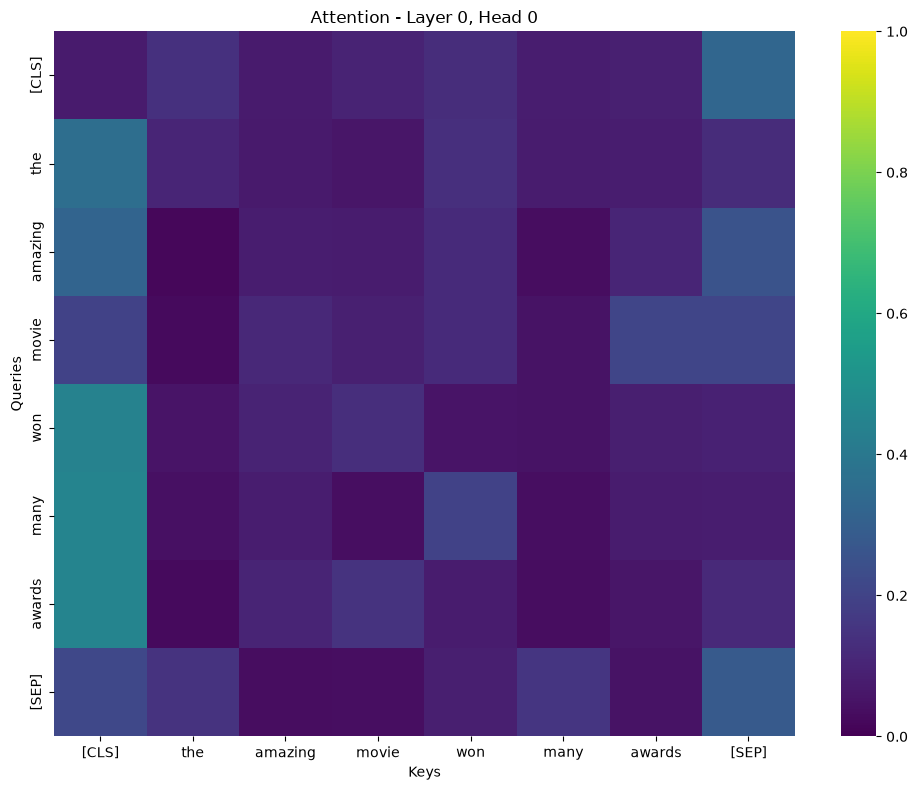

In [16]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

ATTENTION_DIR = Path("artifacts/day03")
ATTENTION_DIR.mkdir(parents=True, exist_ok=True)


def visualize_attention(tokens, attention, layer=0, head=0, filename=None):
    attn = attention[layer][0, head]
    token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"][0].tolist())

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        attn.cpu().numpy(),
        xticklabels=token_list,
        yticklabels=token_list,
        cmap="viridis",
        vmin=0,
        vmax=1,
        cbar=True,
        ax=ax,
    )
    ax.set_title(f"Attention - Layer {layer}, Head {head}")
    ax.set_xlabel("Keys")
    ax.set_ylabel("Queries")
    fig.tight_layout()
    filename = filename or f"attention_layer{layer}_head{head}.png"
    fig.savefig(ATTENTION_DIR / filename)
    plt.show()
    plt.close(fig)


visualize_attention(tokens, outputs.attentions, layer=0, head=0)

## Задача 4. Разные слои

Сравним голову 0 в слоях 0, 3 и 5: номера отсчитываются с нуля. Посмотрите, меняются ли яркие столбцы и распределение весов по строкам. Последние слои не обязаны быть более сфокусированными: это зависит от текста и выбранной головы.

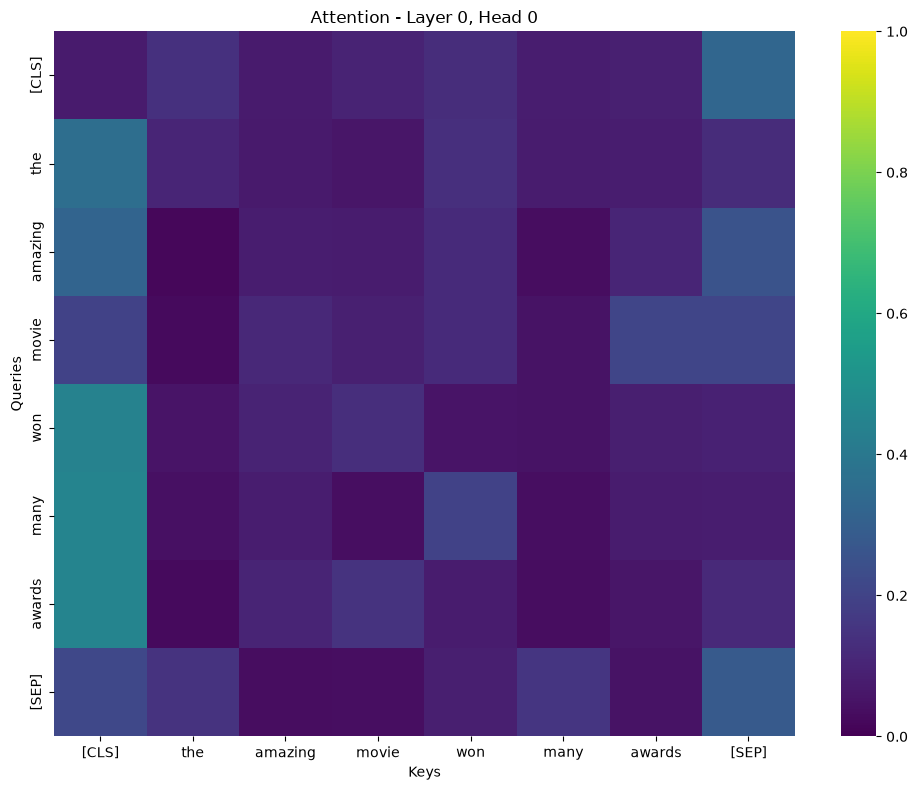

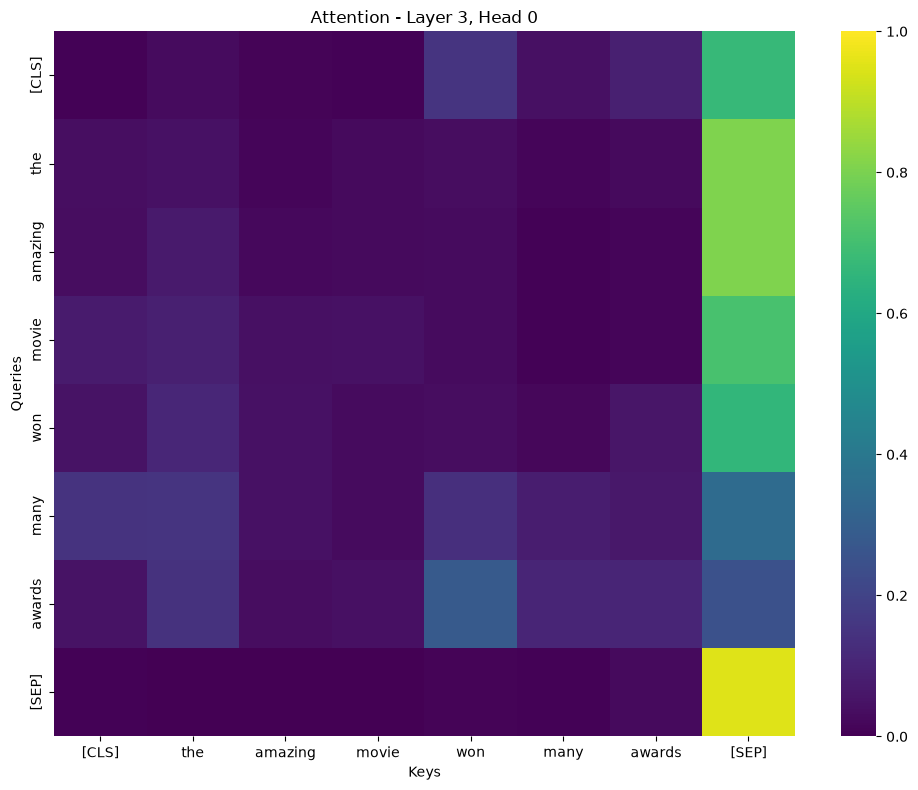

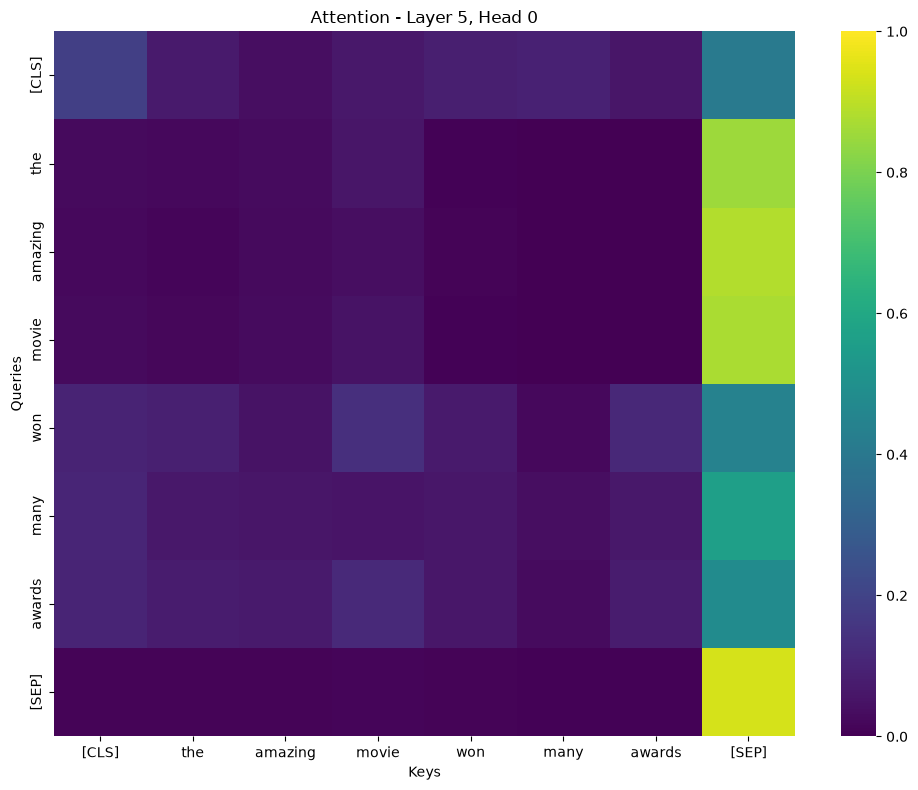

In [17]:
# Первый слой
visualize_attention(tokens, outputs.attentions, layer=0, head=0)

# Средний слой
visualize_attention(tokens, outputs.attentions, layer=3, head=0)

# Последний слой
visualize_attention(tokens, outputs.attentions, layer=5, head=0)

## Задача 5. Разные головы

У нашего DistilBERT **12 голов**, а не 8, как указано в задании. Сохраняем цикл из примера: он покажет первые восемь голов слоя 0.

У каждой головы свои веса. Сравните, какие столбцы выделяются: соседние слова, сам токен или служебные `[CLS]`/`[SEP]`.

Параметры модели: [документация DistilBERT](https://huggingface.co/docs/transformers/v4.57.1/en/model_doc/distilbert).

Всего голов в модели: 12


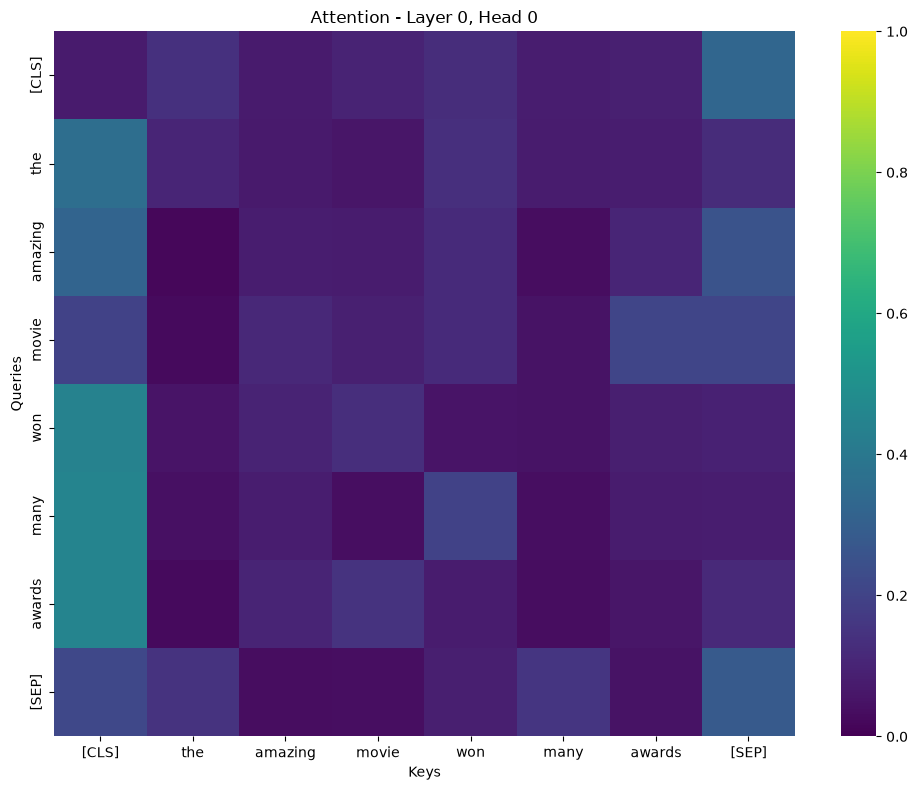

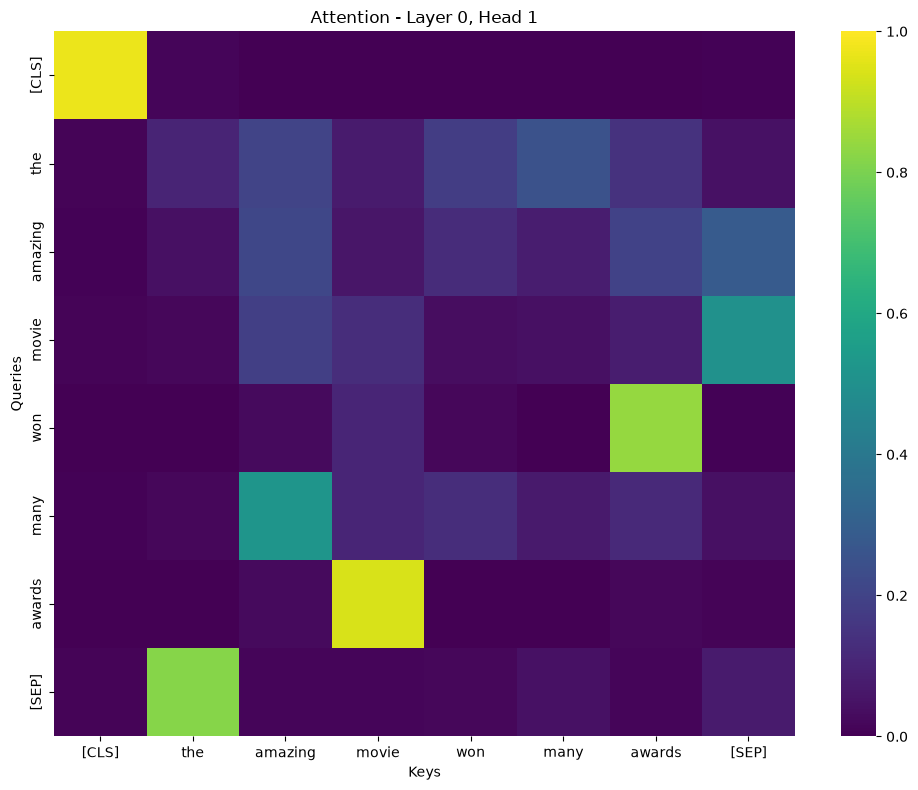

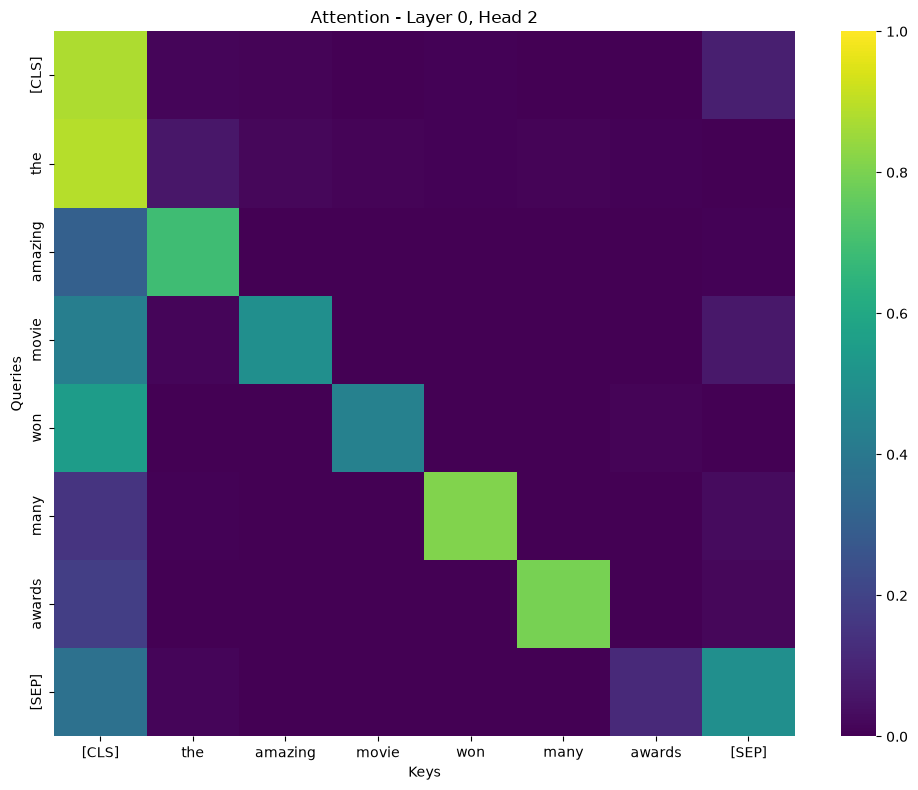

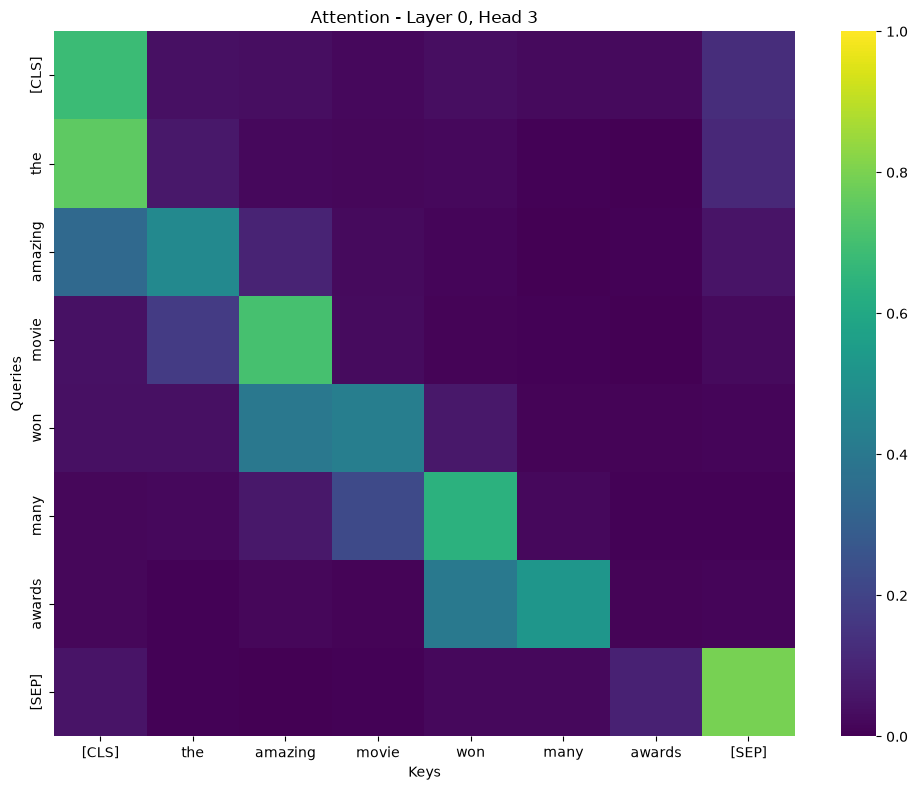

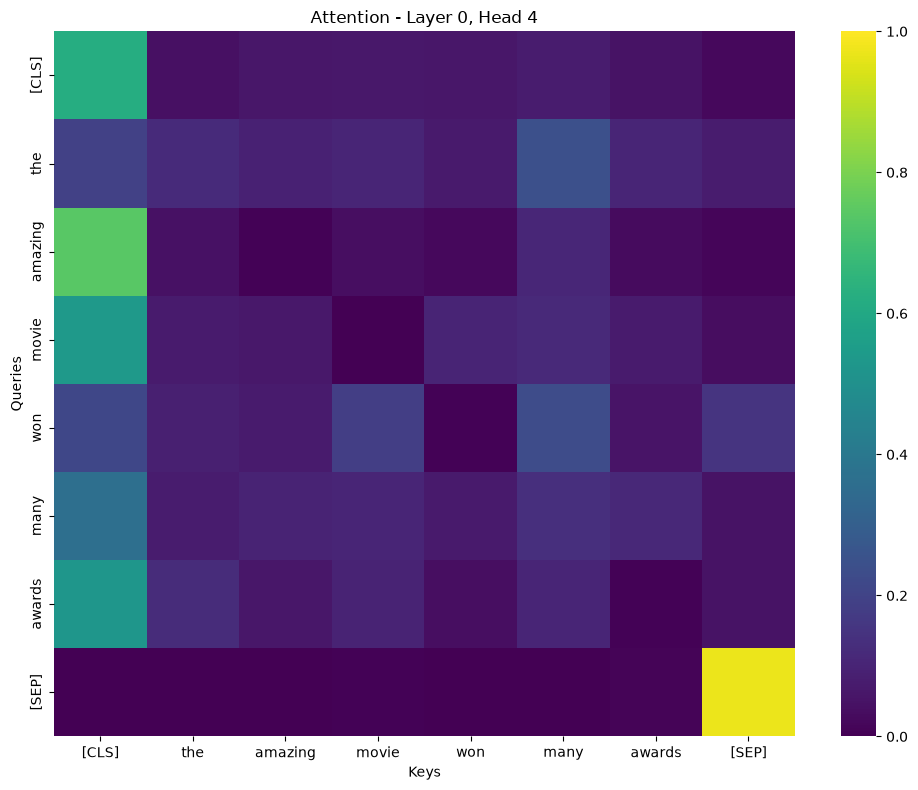

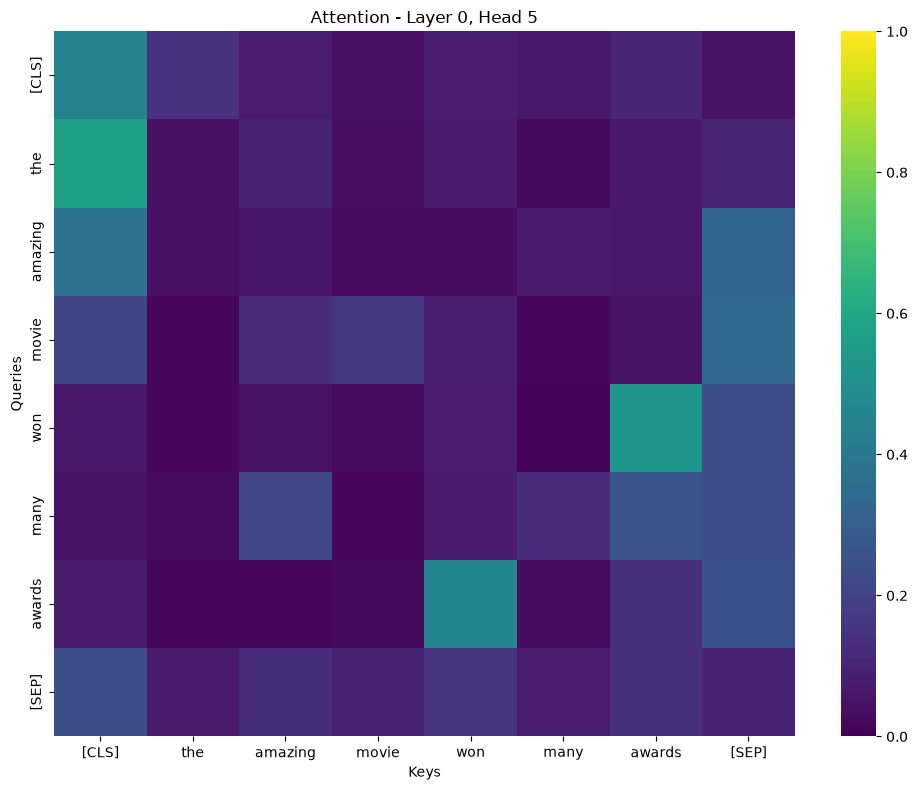

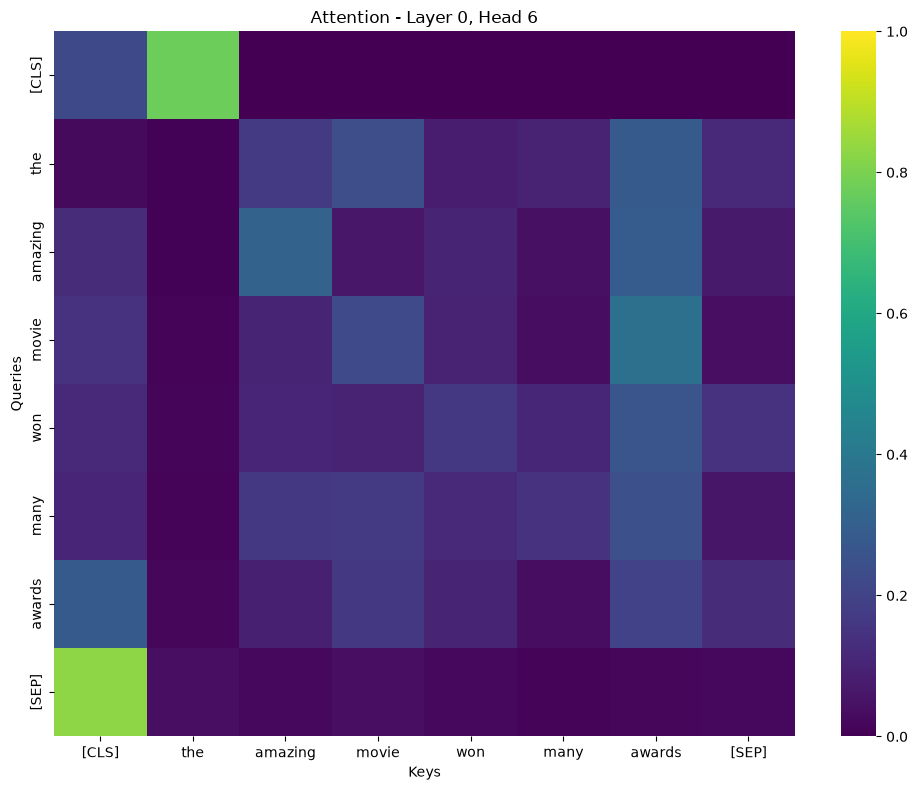

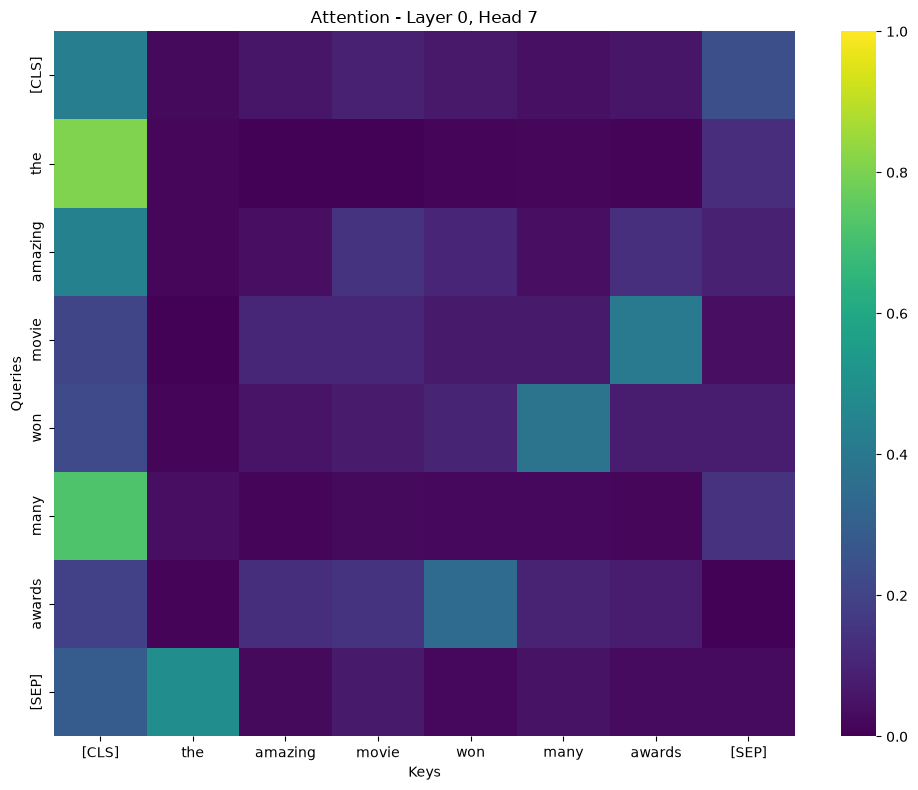

In [18]:
print("Всего голов в модели:", model.config.n_heads)

for head in range(8):
    visualize_attention(tokens, outputs.attentions, layer=0, head=head)

## Задача 6. Внимание к ключевому слову

Берём новый текст со словом `terrible`. На графике найдите **строку `terrible`**: она показывает, от каких позиций этот токен получает информацию в слое 5, голове 0.

После графика выведем столбец с наибольшим весом в этой строке. Максимум может приходиться и на служебный токен. Эти веса описывают одну голову, а не объясняют сами по себе итоговую тональность.

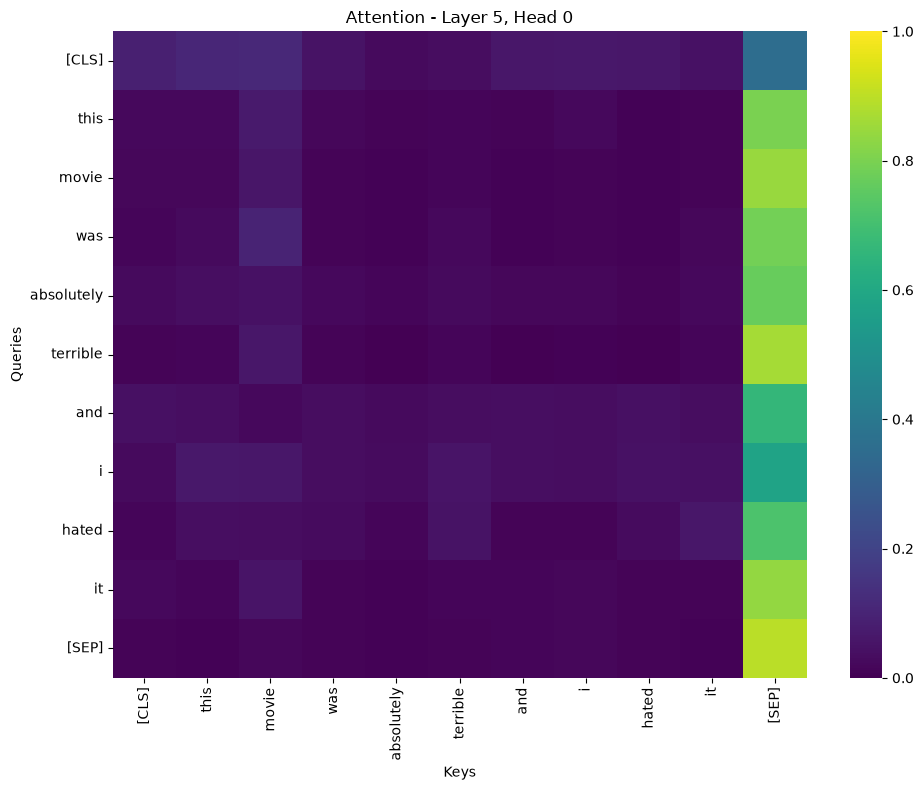

terrible → [SEP]
Вес: 0.866


In [19]:
text = "This movie was absolutely terrible and I hated it"
tokens = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model(**tokens)

visualize_attention(
    tokens, outputs.attentions, layer=5, head=0,
    filename="attention_terrible_layer5_head0.png",
)

token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"][0].tolist())
terrible_position = token_list.index("terrible")
terrible_attention = outputs.attentions[5][0, 0, terrible_position]
max_position = terrible_attention.argmax().item()
print(f"terrible → {token_list[max_position]}")
print(f"Вес: {terrible_attention[max_position].item():.3f}")

**Чекпоинт Дня 3:** получены attention-веса; готова функция `visualize_attention`; построены и сохранены графики разных слоёв и голов. В День 4 используем эмбеддинги для классификации.

# День 4 — Baseline без обучения трансформера

Трансформер превращает тексты в CLS-векторы. На этих векторах обучим отдельную Logistic Regression предсказывать тональность: `0` — negative, `1` — positive. Параметры трансформера не обновляем.

## Задача 1. Токенизация текстов

Используем уже скачанный токенизатор DistilBERT. Как в День 1, передаём токенизатор явно: `padding=True` выравнивает длины внутри батча, `truncation=True` ограничивает вход 128 токенами.

In [1]:
from transformers import AutoTokenizer

model_name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(
    "artifacts/day01/tokenizer", local_files_only=True
)


def tokenize_texts(texts, max_length=128, *, tokenizer):
    return tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    )


example_texts = [
    "Great movie!",
    "Terrible film, waste of time.",
    "I liked the story.",
]
print(tokenize_texts(example_texts, tokenizer=tokenizer))

{'input_ids': tensor([[ 101, 2307, 3185,  999,  102,    0,    0,    0,    0],
        [ 101, 6659, 2143, 1010, 5949, 1997, 2051, 1012,  102],
        [ 101, 1045, 4669, 1996, 2466, 1012,  102,    0,    0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 0, 0]])}


## Задача 2. Извлечение CLS-эмбеддингов

Загружаем базовую модель того же checkpoint без вывода attention-матриц. `eval()` выключает dropout, а `torch.no_grad()` отключает запись операций для градиентов.

Функция обрабатывает тексты батчами. `[:, 0, :]` выбирает CLS-вектор каждого текста. `np.vstack` объединяет батчи: для трёх примеров получится `(3, 768)`. Работаем на CPU.

In [2]:
from transformers import AutoModel
import torch
import numpy as np

model = AutoModel.from_pretrained(
    "artifacts/day02/model", local_files_only=True,
    output_attentions=False,
)
model.eval()


def get_cls_embeddings(texts, batch_size=32):
    all_embeddings = []
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        tokens = tokenize_texts(batch_texts, tokenizer=tokenizer)

        with torch.no_grad():
            outputs = model(**tokens)

        cls_embeddings = outputs.last_hidden_state[:, 0, :]
        all_embeddings.append(cls_embeddings.cpu().numpy())

    return np.vstack(all_embeddings)


example_embeddings = get_cls_embeddings(example_texts)
print("Форма эмбеддингов:", example_embeddings.shape)

Форма эмбеддингов: (3, 768)


## Задача 3. Logistic Regression на эмбеддингах

Берём подготовленный CSV из 5 000 примеров `data/processed/train.csv`. Для этого задания разделим его заново на 80%/20%, как указано в условии. Файлы `validation.csv` и `test.csv` здесь не используем.

`texts` — входные строки, `y` — правильные ответы. Получение эмбеддингов для всех текстов на CPU займёт больше времени, чем примеры выше.

In [3]:
import pandas as pd

df = pd.read_csv("data/processed/train.csv")
texts = df["text"].tolist()
y = df["label"].tolist()
print("Количество текстов:", len(texts))

X = get_cls_embeddings(texts)
print("Форма X:", X.shape)

Количество текстов: 5000


Форма X: (5000, 768)


Разделяем векторы вместе с метками. `stratify=y` сохраняет доли классов, а `random_state=42` фиксирует разбиение. Обучающая часть содержит 4 000 примеров, проверочная — 1 000.

Классификатор назовём `classifier`, чтобы не заменить переменную `model`, в которой хранится трансформер. `.fit()` обучает только Logistic Regression; `.predict()` выдаёт классы для проверочной части.

`n_jobs=-1` оставлен по заданию. В установленной версии scikit-learn он уже не влияет на расчёт, поэтому появляется предупреждение ([документация](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

classifier = LogisticRegression(max_iter=1000, n_jobs=-1)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

# Сохраняем baseline и способ получения CLS-признаков для Дня 6.
import joblib
from baseline_features import CLSVectorizer

joblib.dump(classifier, "baseline_model.pkl")
joblib.dump(CLSVectorizer(), "vectorizer.pkl")

`classification_report` показывает precision, recall и F1 для каждого класса. Macro F1 — среднее F1 двух классов с равным весом. Сохраняем этот результат и отчёт в `baseline_results.txt` рядом с ноутбуком.

In [5]:
from sklearn.metrics import classification_report, f1_score

report = classification_report(y_test, y_pred)
print(report)

f1 = f1_score(y_test, y_pred, average="macro")
print(f"Macro F1: {f1:.4f}")

with open("baseline_results.txt", "w", encoding="utf-8") as file:
    file.write("Baseline: DistilBERT CLS + Logistic Regression\n")
    file.write("Dataset: data/processed/train.csv; split 80/20; random_state=42\n")
    file.write(f"Train: {len(y_train)}; test: {len(y_test)}\n")
    file.write(f"Macro F1: {f1:.6f}\n\n")
    file.write(report)

print("Сохранено: baseline_results.txt")

              precision    recall  f1-score   support

           0       0.85      0.82      0.84       443
           1       0.86      0.89      0.87       557

    accuracy                           0.86      1000
   macro avg       0.86      0.85      0.85      1000
weighted avg       0.86      0.86      0.86      1000

Macro F1: 0.8546
Сохранено: baseline_results.txt


# День 5 — Fine-tuning модели

В День 4 обучали только Logistic Regression на готовых векторах. Сегодня обновляем параметры самого трансформера и его классификатора по правильным меткам отзывов.

## Задача 1. Класс SentimentDataset

`__len__` возвращает количество примеров. `__getitem__` берёт один текст и метку, токенизирует текст и возвращает тензоры.

`padding="max_length"` делает длину каждого входа равной 128. `flatten()` убирает лишнее измерение: из `[1, 128]` получаем `[128]`. `labels` — правильный класс `0` или `1`.

In [1]:
import torch
from torch.utils.data import Dataset
from transformers import AutoTokenizer

# Тот же токенизатор, что использовали в предыдущих днях.
model_name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(
    "artifacts/day01/tokenizer", local_files_only=True
)
torch.manual_seed(42)


class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]
        encoding = self.tokenizer(
            text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt",
        )
        return {
            "input_ids": encoding["input_ids"].flatten(),
            "attention_mask": encoding["attention_mask"].flatten(),
            "labels": torch.tensor(label, dtype=torch.long),
        }

## Задача 2. Загрузка и разделение данных

Используем те же 5 000 строк из `train.csv` и такое же разбиение 80/20 с `random_state=42`, как в День 4: 4 000 примеров для обучения, 1 000 для validation. `stratify` сохраняет доли классов.

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/processed/train.csv")
texts = df["text"].tolist()
labels = df["label"].tolist()

train_texts, val_texts, train_labels, val_labels = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=labels
)
train_dataset = SentimentDataset(train_texts, train_labels, tokenizer)
val_dataset = SentimentDataset(val_texts, val_labels, tokenizer)
print("Train:", len(train_dataset), "Validation:", len(val_dataset))

Train: 4000 Validation: 1000


## Задача 3. Модель для классификации и DataLoader

`AutoModelForSequenceClassification` добавляет к трансформеру классификатор на два класса. Его новые параметры начинают со случайных значений — сообщение `newly initialized` при загрузке ожидаемо.

DataLoader собирает примеры в батчи по 16. `shuffle=True` перемешивает обучающие примеры перед каждой эпохой.

In [3]:
from transformers import AutoModelForSequenceClassification
from torch.utils.data import DataLoader

num_labels = len(set(labels))
model = AutoModelForSequenceClassification.from_pretrained(
    "artifacts/day02/model",
    local_files_only=True,
    num_labels=num_labels,
    output_attentions=False,
    id2label={0: "negative", 1: "positive"},
    label2id={"negative": 0, "positive": 1},
)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at artifacts/day02/model and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


## Задача 4. Оптимизатор и устройство

Используем `AdamW` из `torch.optim`: импорт из `transformers` в нашей версии недоступен. `lr=2e-5` задаёт размер шага обновления параметров.

Выбираем CUDA, GPU Apple Silicon (`mps`) или CPU. Сначала переносим модель на устройство, затем создаём оптимизатор для всех её параметров.

In [4]:
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

model.to(device)
optimizer = AdamW(model.parameters(), lr=2e-5)
print("Устройство:", device)

Устройство: mps


## Задача 5. Обучение одной эпохи

Эпоха — один проход по всем обучающим примерам. Для каждого батча:

- `zero_grad()` очищает градиенты прошлого шага;
- модель получает тексты и правильные метки, вычисляет ошибку `loss`;
- `loss.backward()` вычисляет градиенты;
- `optimizer.step()` обновляет параметры модели.

Именно здесь происходит обучение. Функция возвращает среднюю ошибку по батчам.

In [5]:
def train_epoch(model, dataloader, optimizer, device):
    model.train()
    total_loss = 0
    for batch in dataloader:
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels,
        )
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    return total_loss / len(dataloader)

## Задача 6. Оценка модели

Здесь параметры не меняем: включаем `eval()` и `no_grad()`. `outputs.logits` содержит оценки классов. `argmax(dim=1)` выбирает класс с большей оценкой для каждого текста.

Сравниваем предсказания с метками: accuracy — доля правильных ответов, macro F1 — среднее F1 классов.

In [6]:
def evaluate(model, dataloader, device):
    model.eval()
    predictions = []
    true_labels = []
    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
            )
            preds = torch.argmax(outputs.logits, dim=1)
            predictions.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average="macro")
    return accuracy, f1

## Задача 7. Три эпохи обучения

Каждую эпоху сначала обучаем модель на train, затем проверяем на validation. Validation не участвует в обновлении параметров. При повторном запуске только этой ячейки обучение продолжится с текущих весов; для нового запуска с нуля начните с загрузки модели в задаче 3.

In [7]:
num_epochs = 3

for epoch in range(num_epochs):
    train_loss = train_epoch(model, train_loader, optimizer, device)
    val_acc, val_f1 = evaluate(model, val_loader, device)
    print(f"Epoch {epoch + 1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Accuracy: {val_acc:.4f}")
    print(f"Val F1: {val_f1:.4f}")
    print("-" * 50)

Epoch 1/3
Train Loss: 0.3899
Val Accuracy: 0.8960
Val F1: 0.8952
--------------------------------------------------


Epoch 2/3
Train Loss: 0.1813
Val Accuracy: 0.8990
Val F1: 0.8964
--------------------------------------------------


Epoch 3/3
Train Loss: 0.0855
Val Accuracy: 0.9090
Val F1: 0.9075
--------------------------------------------------


## Задача 8. Сохранение модели и метрик

Сохраняем веса после третьей эпохи и токенизатор в `fine_tuned_model`. В `fine_tuned_results.txt` записываем финальные метрики validation — они понадобятся для сравнения с baseline.

In [8]:
model.save_pretrained("./fine_tuned_model")
tokenizer.save_pretrained("./fine_tuned_model")

with open("fine_tuned_results.txt", "w", encoding="utf-8") as file:
    file.write(f"Final Validation F1: {val_f1:.4f}\n")
    file.write(f"Final Validation Accuracy: {val_acc:.4f}\n")

print("Модель сохранена в fine_tuned_model")
print("Метрики сохранены в fine_tuned_results.txt")

Модель сохранена в fine_tuned_model
Метрики сохранены в fine_tuned_results.txt


# День 6 — Инференс и сравнение моделей

Сравниваем baseline Дня 4 и fine-tuned модель Дня 5 на одинаковых примерах. Инференс — получение предсказаний без обучения и изменения параметров.

## Задача 1. Загрузка моделей

Загружаем fine-tuned модель и токенизатор из `fine_tuned_model`. Baseline загружаем из `baseline_model.pkl`.

У нас baseline использует CLS-векторы DistilBERT. Поэтому `vectorizer.pkl` хранит адаптер, чей `.transform(texts)` получает те же векторы через код `baseline_features.py`. Сохранение этих файлов добавлено в День 4; текущий baseline восстановлен с теми же данными и параметрами.

In [1]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer
import torch
import joblib

model_ft = AutoModelForSequenceClassification.from_pretrained(
    "./fine_tuned_model", local_files_only=True
)
tokenizer = AutoTokenizer.from_pretrained("./fine_tuned_model", local_files_only=True)
model_ft.eval()

baseline_model = joblib.load("baseline_model.pkl")
baseline_vectorizer = joblib.load("vectorizer.pkl")

## Задача 2. Предсказания fine-tuned модели

Принимаем строку или список строк. `softmax` превращает оценки классов в вероятности, а `argmax` выбирает класс с большей вероятностью. Порядок вероятностей: `0` — negative, `1` — positive. Работаем на CPU, без градиентов.

In [2]:
def predict_fine_tuned(texts, model, tokenizer):
    if isinstance(texts, str):
        texts = [texts]
    predictions = []
    for text in texts:
        inputs = tokenizer(
            text, return_tensors="pt", truncation=True, max_length=128
        )
        with torch.no_grad():
            outputs = model(**inputs)
        probs = torch.nn.functional.softmax(outputs.logits, dim=1)
        pred = torch.argmax(probs, dim=1).item()
        predictions.append({
            "text": text,
            "prediction": pred,
            "probabilities": probs[0].cpu().numpy(),
        })
    return predictions

## Задача 3. Предсказания baseline

`vectorizer.transform()` превращает тексты в CLS-векторы. Logistic Regression по ним предсказывает классы и вероятности. `clean_func` позволяет передать очистку текста, но для нашего baseline она не нужна.

In [3]:
def predict_baseline(texts, model, vectorizer, clean_func=None):
    if isinstance(texts, str):
        texts = [texts]
    if clean_func:
        texts = [clean_func(text) for text in texts]

    X = vectorizer.transform(texts)
    predictions = model.predict(X)
    probs = model.predict_proba(X) if hasattr(model, "predict_proba") else None
    results = []
    for i, text in enumerate(texts):
        results.append({
            "text": text,
            "prediction": int(predictions[i]),
            "probabilities": probs[i] if probs is not None else None,
        })
    return results

## Задача 4. Сравнение на пяти примерах

Тестовые фразы заданы в списке ниже. Обе модели выбирают между `0` и `1`; отдельного нейтрального класса в нашем датасете нет. Совпадение двух предсказаний само по себе не доказывает их правильность.

In [4]:
test_texts = [
    "This movie was absolutely fantastic!",
    "Terrible, waste of my time.",
    "It was okay, nothing special.",
    "Best film I've seen this year!",
    "Boring and too long.",
]
preds_ft = predict_fine_tuned(test_texts, model_ft, tokenizer)
preds_baseline = predict_baseline(test_texts, baseline_model, baseline_vectorizer)

for i, text in enumerate(test_texts):
    print(f"\nТекст: {text}")
    print(f'Fine-tuned: {preds_ft[i]["prediction"]} (probs: {preds_ft[i]["probabilities"]})')
    print(f'Baseline: {preds_baseline[i]["prediction"]} (probs: {preds_baseline[i]["probabilities"]})')
    print(f'Совпадают: {preds_ft[i]["prediction"] == preds_baseline[i]["prediction"]}')


Текст: This movie was absolutely fantastic!
Fine-tuned: 1 (probs: [0.0050028  0.99499714])
Baseline: 1 (probs: [0.00174993 0.99825007])
Совпадают: True

Текст: Terrible, waste of my time.
Fine-tuned: 0 (probs: [0.996241   0.00375907])
Baseline: 0 (probs: [0.99786794 0.00213204])
Совпадают: True

Текст: It was okay, nothing special.
Fine-tuned: 1 (probs: [0.4568723  0.54312766])
Baseline: 1 (probs: [0.26451993 0.73548007])
Совпадают: True

Текст: Best film I've seen this year!
Fine-tuned: 1 (probs: [0.00311349 0.99688655])
Baseline: 1 (probs: [7.560253e-04 9.992440e-01])
Совпадают: True

Текст: Boring and too long.
Fine-tuned: 0 (probs: [0.9951239  0.00487612])
Baseline: 0 (probs: [0.99860686 0.00139315])
Совпадают: True


## Задача 5. Confusion matrix для обеих моделей

Восстанавливаем ту же проверочную тысячу примеров через разбиение 80/20 с `random_state=42`. В День 5 она была validation, поэтому это сравнение на знакомой проверочной части, а не на независимом финальном test.

В матрице строки — правильные классы, столбцы — предсказанные. На диагонали стоят правильные ответы, вне диагонали — ошибки. Сохраняем два PNG.

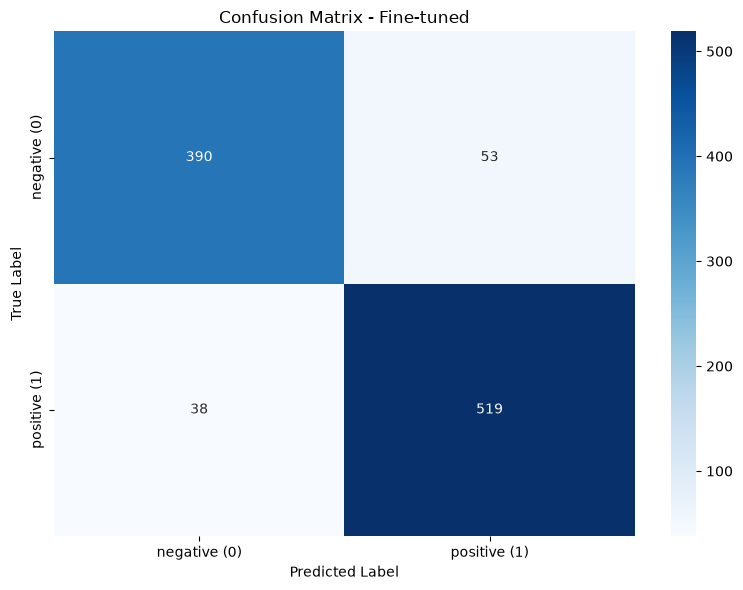

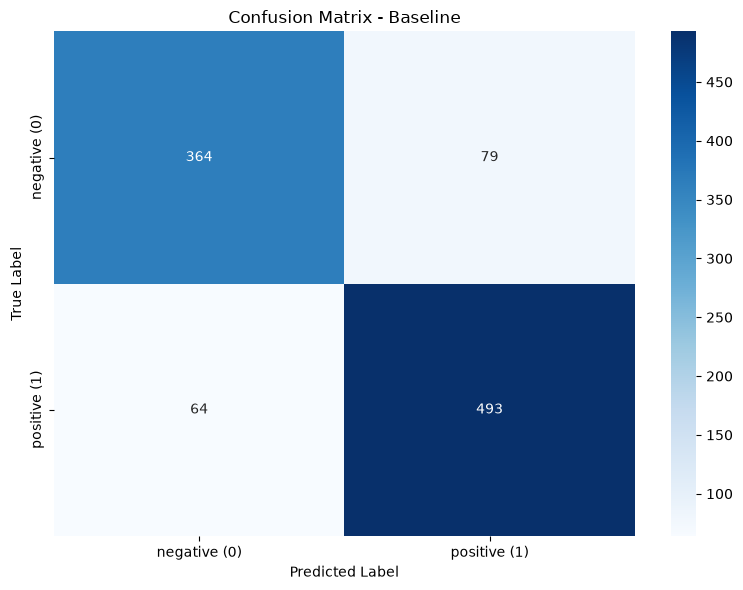

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/processed/train.csv")
_, test_df, _, _ = train_test_split(
    df, df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)
test_texts = test_df["text"].tolist()
test_labels = test_df["label"].tolist()

preds_ft_all = predict_fine_tuned(test_texts, model_ft, tokenizer)
y_pred_ft = [prediction["prediction"] for prediction in preds_ft_all]
preds_baseline_all = predict_baseline(test_texts, baseline_model, baseline_vectorizer)
y_pred_base = [prediction["prediction"] for prediction in preds_baseline_all]

cm_ft = confusion_matrix(test_labels, y_pred_ft, labels=[0, 1])
cm_base = confusion_matrix(test_labels, y_pred_base, labels=[0, 1])

for name, cm, filename in [
    ("Fine-tuned", cm_ft, "confusion_matrix_finetuned.png"),
    ("Baseline", cm_base, "confusion_matrix_baseline.png"),
]:
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["negative (0)", "positive (1)"],
        yticklabels=["negative (0)", "positive (1)"],
        ax=ax,
    )
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_ylabel("True Label")
    ax.set_xlabel("Predicted Label")
    fig.tight_layout()
    fig.savefig(filename)
    plt.show()
    plt.close(fig)

## Задача 6. Сравнение метрик

Считаем отчёт, macro F1 и accuracy по одинаковым правильным меткам для обеих моделей. «Улучшение F1» ниже — относительный прирост в процентах, а не разница в процентных пунктах.

In [6]:
from sklearn.metrics import classification_report, f1_score, accuracy_score

print("=== Fine-tuned Model ===")
report_ft = classification_report(test_labels, y_pred_ft)
print(report_ft)
f1_ft = f1_score(test_labels, y_pred_ft, average="macro")
acc_ft = accuracy_score(test_labels, y_pred_ft)

print("\n=== Baseline Model ===")
report_base = classification_report(test_labels, y_pred_base)
print(report_base)
f1_base = f1_score(test_labels, y_pred_base, average="macro")
acc_base = accuracy_score(test_labels, y_pred_base)

improvement = (f1_ft - f1_base) / f1_base * 100
print("\n=== Сравнение ===")
print(f"Fine-tuned F1: {f1_ft:.4f}, Accuracy: {acc_ft:.4f}")
print(f"Baseline F1: {f1_base:.4f}, Accuracy: {acc_base:.4f}")
print(f"Улучшение F1: {improvement:.2f}%")

=== Fine-tuned Model ===
              precision    recall  f1-score   support

           0       0.91      0.88      0.90       443
           1       0.91      0.93      0.92       557

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000


=== Baseline Model ===
              precision    recall  f1-score   support

           0       0.85      0.82      0.84       443
           1       0.86      0.89      0.87       557

    accuracy                           0.86      1000
   macro avg       0.86      0.85      0.85      1000
weighted avg       0.86      0.86      0.86      1000


=== Сравнение ===
Fine-tuned F1: 0.9075, Accuracy: 0.9090
Baseline F1: 0.8546, Accuracy: 0.8570
Улучшение F1: 6.19%


## Задача 7. Сохранение сравнения

Записываем метрики обеих моделей и относительный прирост F1 в `comparison_results.txt`.

In [7]:
with open("comparison_results.txt", "w", encoding="utf-8") as file:
    file.write("=== Сравнение моделей ===\n\n")
    file.write("Данные: data/processed/train.csv, split 80/20, random_state=42\n")
    file.write("Оценка на 1000 примерах validation Дня 5\n\n")
    file.write("Fine-tuned Model:\n")
    file.write(f"  F1 (macro): {f1_ft:.4f}\n")
    file.write(f"  Accuracy: {acc_ft:.4f}\n")
    file.write("\nBaseline Model:\n")
    file.write(f"  F1 (macro): {f1_base:.4f}\n")
    file.write(f"  Accuracy: {acc_base:.4f}\n")
    file.write(f"\nУлучшение F1: {improvement:.2f}%\n")

print("Сохранено: comparison_results.txt")

Сохранено: comparison_results.txt


# День 7 — Анализ ошибок и мини-приложение

Продолжайте после Дня 6: используем те же `test_texts`, `test_labels` и `y_pred_ft`. Проверочная тысяча — validation Дня 5. Анализируем fine-tuned модель и запускаем Gradio-демо.

## Задача 1. False Positive и False Negative

Собираем текст, правильную метку и предсказание в таблицу. Ошибка — строки с разными метками.

**FP:** предсказали `1` (positive), правильно `0` (negative). **FN:** предсказали `0`, правильно `1`. В нашем датасете нет neutral.

In [4]:
import pandas as pd

df_test = pd.DataFrame({
    "text": test_texts,
    "true_label": test_labels,
    "pred_label": y_pred_ft,
})
errors = df_test[df_test["true_label"] != df_test["pred_label"]].copy()
fp = errors[(errors["pred_label"] == 1) & (errors["true_label"] == 0)]
fn = errors[(errors["pred_label"] == 0) & (errors["true_label"] == 1)]

print(f"Всего ошибок: {len(errors)}")
print(f"False Positives: {len(fp)}")
print(f"False Negatives: {len(fn)}")

Всего ошибок: 91
False Positives: 53
False Negatives: 38


## Задача 2. Паттерны ошибок

Выводим первые пять FP и FN. Длину считаем в символах через `.str.len()`, а не в токенах. `.copy()` выше позволяет добавить столбец без изменения исходной таблицы.

In [5]:
print("\n=== FALSE POSITIVES: предсказано positive, правильно negative ===")
for idx, row in fp.head(5).iterrows():
    print(f'\nТекст: {row["text"]}')
    print(f'Истинный класс: {row["true_label"]}, Предсказан: {row["pred_label"]}')

print("\n=== FALSE NEGATIVES: предсказано negative, правильно positive ===")
for idx, row in fn.head(5).iterrows():
    print(f'\nТекст: {row["text"]}')
    print(f'Истинный класс: {row["true_label"]}, Предсказан: {row["pred_label"]}')

errors["text_length"] = errors["text"].str.len()
mean_error_length = errors["text_length"].mean()
mean_all_length = df_test["text"].str.len().mean()
print(f"\nСредняя длина ошибочных текстов: {mean_error_length:.0f}")
print(f"Средняя длина всех текстов: {mean_all_length:.0f}")


=== FALSE POSITIVES: предсказано positive, правильно negative ===

Текст: ` it looks good , sonny , but you missed the point . '
Истинный класс: 0, Предсказан: 1

Текст: is enough to save oleander 's uninspired story .
Истинный класс: 0, Предсказан: 1

Текст: preachy and
Истинный класс: 0, Предсказан: 1

Текст: losin ' his fan base
Истинный класс: 0, Предсказан: 1

Текст: the simpering soundtrack and editing
Истинный класс: 0, Предсказан: 1

=== FALSE NEGATIVES: предсказано negative, правильно positive ===

Текст: rugrats
Истинный класс: 1, Предсказан: 0

Текст: in fact , even better .
Истинный класс: 1, Предсказан: 0

Текст: 'll end up moved
Истинный класс: 1, Предсказан: 0

Текст: the theater in the first 10 minutes
Истинный класс: 1, Предсказан: 0

Текст: his penchant for tearing up on cue --
Истинный класс: 1, Предсказан: 0

Средняя длина ошибочных текстов: 45
Средняя длина всех текстов: 54


В примерах встречаются обрывки фраз и название `rugrats`, которым не хватает контекста. В FP с `looks good ... but you missed the point` положительное выражение сочетается с критикой. Есть и FN с явным положительным словом `better`.

Ошибочные тексты в среднем короче всей выборки: примерно 45 против 54 символов. Эти наблюдения не доказывают причину каждой ошибки, но показывают, какие случаи стоит изучить. Запишем их вместе с примерами в отчёт.

In [6]:
observations = [
    "В примерах есть обрывки фраз и названия без контекста: rugrats, preachy and.",
    "В FP встречается смешанная оценка: looks good ... but you missed the point.",
    "Есть FN с положительными словами, например in fact , even better .",
    f"Средняя длина ошибок: {mean_error_length:.1f} символа; всех текстов: {mean_all_length:.1f}.",
    "По одной средней длине нельзя утверждать, что короткие тексты ошибочны чаще.",
    "FP больше, чем FN: модель чаще ошибочно относит negative к positive, чем наоборот.",
    "Проверочная часть уже использовалась как validation при fine-tuning.",
]

with open("error_analysis.txt", "w", encoding="utf-8") as file:
    file.write("=== АНАЛИЗ ОШИБОК ===\n\n")
    file.write(f"Всего примеров: {len(df_test)}\n")
    file.write(f"Всего ошибок: {len(errors)}\n")
    file.write(f"False Positives: {len(fp)}\n")
    file.write(f"False Negatives: {len(fn)}\n\n")
    for title, examples in [("FALSE POSITIVES", fp), ("FALSE NEGATIVES", fn)]:
        file.write(f"=== ПРИМЕРЫ {title} ===\n")
        for idx, row in examples.head(5).iterrows():
            file.write(f'\nТекст: {row["text"]}\n')
            file.write(f'Истинный: {row["true_label"]}, Предсказан: {row["pred_label"]}\n')
        file.write("\n")
    file.write("=== НАБЛЮДЕНИЯ ===\n")
    for observation in observations:
        file.write(f"- {observation}\n")

print("Сохранено: error_analysis.txt")

Сохранено: error_analysis.txt


## Задача 3. Gradio-приложение

Файл `app.py` загружает сохранённую модель, токенизирует введённый текст, получает вероятности через softmax и выводит класс. Соответствие меток исправлено для нашего набора: `0 = Negative`, `1 = Positive`.

Gradio установлен в `.venv`. Для нового окружения используйте `python -m pip install -r requirements.txt`. В отдельном терминале VS Code из папки проекта:

```bash
.venv/bin/python app.py
```

Откройте [http://127.0.0.1:7860](http://127.0.0.1:7860). Введите отзыв на английском языке. Следующая ячейка проверяет ту же функцию без запуска сервера внутри ноутбука.

In [7]:
from app import predict_sentiment

print(predict_sentiment("This movie was absolutely amazing!"))

Prediction: Positive

Probabilities:
Negative: 0.49%
Positive: 99.51%



## Задача 4. Альтернатива FastAPI — опционально

Для этого проекта выбран Gradio. Он уже предоставляет нужную форму ввода и вывод предсказания.

## Задача 5. README

В `README.md` описаны проект, файлы, запуск демо, пример использования модели и фактические метрики. Все семь дней находятся в этом ноутбуке.

**Чекпоинт:** готовы `error_analysis.txt`, `app.py`, `README.md`, сохранённая модель и результаты сравнения.